# A neural network from scratch, in NumPy

Last session: a neural network is a function with lots of knobs (weights and biases), and it learns by
**starting random and nudging the knobs to reduce its error**. Today we build one, with nothing but NumPy,
and go through every step one at a time.

**The whole recipe:**

| Step | Name | In one sentence |
|---|---|---|
| 0 | **Data** | the examples we want to learn from: inputs $x$ and correct answers $y$ |
| 1 | **Initialise** | pick an architecture and give every weight and bias a random starting value |
| 2 | **Forward pass** | push the inputs through the network to get a prediction $\hat y$ |
| 3 | **Loss** | one number saying how wrong the predictions are |
| 4 | **Backward pass (backpropagation)** | for every weight and bias, work out which way to nudge it to reduce the loss |
| 5 | **Update (gradient descent)** | nudge each weight and bias that way, a little |
| 6 | **Repeat** | steps 2 to 5, many times |
| 7 | **Predict** | use the trained network on new inputs |

That's it. Every neural network you have heard of, from a 10-line toy to a language model, does exactly these steps.
Ours is just small enough to read.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False,
})

## Step 0: Data

We need something to learn. Let's keep it tiny: one input $x$, one output $y$, and the relationship is $y = x^2$ plus a bit of noise.
We know the answer, which makes it easy to check whether the network really learned it.

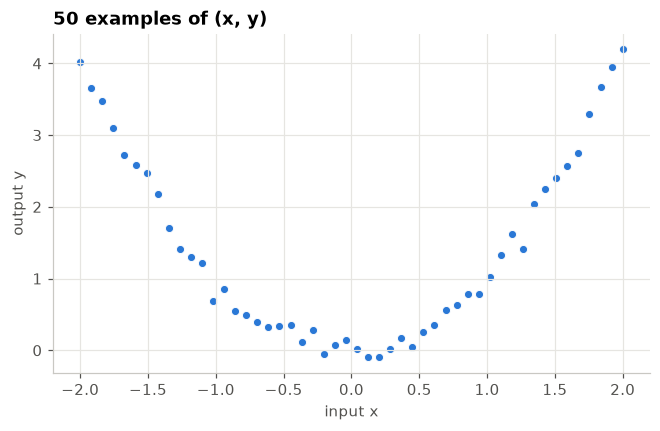

x shape: (50, 1)    y shape: (50, 1)


In [2]:
x = np.linspace(-2, 2, 50).reshape(-1, 1)          # 50 inputs, as a column  (shape 50 × 1)
y = x ** 2 + rng.normal(scale=0.15, size=x.shape)  # 50 correct answers       (shape 50 × 1)

fig, ax = plt.subplots()
ax.scatter(x, y, s=28, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set(xlabel="input x", ylabel="output y", title="50 examples of (x, y)")
plt.show()
print("x shape:", x.shape, "   y shape:", y.shape)

## Step 1: Initialise (architecture + random weights)

The smallest network that can bend: **1 input → 4 hidden neurons → 1 output**.

<div align="center">

```
 x ──┬──▶ (h1) ──┐
     ├──▶ (h2) ──┤
     ├──▶ (h3) ──┤
     └──▶ (h4) ──┘

──▶ (ŷ)
```

</div>

Every arrow is a **weight**, every neuron has a **bias**. We store them in four arrays:

| Array | Shape | Meaning |
|---|---|---|
| `W1` | 1 × 4 | one weight from the input to each hidden neuron |
| `b1` | 1 × 4 | one bias per hidden neuron |
| `W2` | 4 × 1 | one weight from each hidden neuron to the output |
| `b2` | 1 × 1 | the output's bias |

That is **13 knobs** in total. They start as small random numbers (biases can start at zero).

In [3]:
W1 = rng.normal(size=(1, 4))     # input  → hidden
b1 = np.zeros((1, 4))
W2 = rng.normal(size=(4, 1))     # hidden → output
b2 = np.zeros((1, 1))

print("W1 =", W1)
print("b1 =", b1)
print("W2 =", W2.T, "(shown transposed)")
print("b2 =", b2)
print("total knobs:", W1.size + b1.size + W2.size + b2.size)

W1 = [[ 0.357 -1.208 -0.004  0.656]]
b1 = [[0. 0. 0. 0.]]
W2 = [[-1.288  0.395  0.43   0.696]] (shown transposed)
b2 = [[0.]]
total knobs: 13


## Step 2: Forward pass

Push the inputs through, layer by layer. Each layer does the same two things:
**weighted sum + bias**, then **squish** (the activation function). We use `tanh` as the squish.

$$
\begin{aligned}
z_1 &= x\,W_1 + b_1 &&\text{(hidden layer: weighted sums)}\\
h   &= \tanh(z_1)   &&\text{(hidden layer: squish)}\\
\hat y &= h\,W_2 + b_2 &&\text{(output layer: weighted sum, no squish because } y \text{ can be any number)}
\end{aligned}
$$

Because `x` holds all 50 examples stacked as rows, one matrix multiplication does all 50 at once.

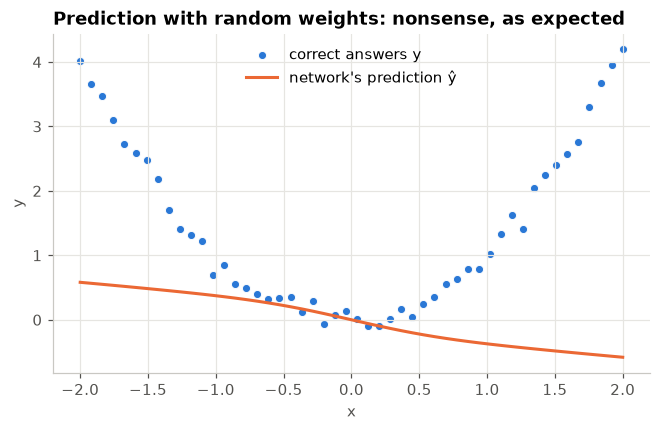

In [4]:
def forward(x, W1, b1, W2, b2):
    z1 = x @ W1 + b1          # (50×1) @ (1×4) + (1×4)  →  50×4
    h  = np.tanh(z1)          #                          →  50×4
    y_hat = h @ W2 + b2       # (50×4) @ (4×1) + (1×1)  →  50×1
    return y_hat, h           # we keep h: the backward pass needs it

y_hat, h = forward(x, W1, b1, W2, b2)

fig, ax = plt.subplots()
ax.scatter(x, y, s=28, color=BLUE, edgecolor="white", linewidth=0.6, label="correct answers y")
ax.plot(x, y_hat, color=ORANGE, linewidth=2, label="network's prediction ŷ")
ax.set(xlabel="x", ylabel="y", title="Prediction with random weights: nonsense, as expected")
ax.legend(loc="upper center")
plt.show()

## Step 3: Loss

We need **one number** that says how wrong we are, so we have something to make smaller.
Take every example's error $(\hat y - y)$, square it (so negative and positive errors don't cancel), and average:

$$L = \frac{1}{n}\sum_{i=1}^{n} (\hat y_i - y_i)^2 \qquad \text{(mean squared error)}$$

In [5]:
def loss(y_hat, y):
    return np.mean((y_hat - y) ** 2)

print(f"loss with random weights = {loss(y_hat, y):.3f}")

loss with random weights = 3.848


## Step 4: Backward pass (backpropagation)

The question for each of the 13 knobs: *if I nudge **this** knob up a tiny bit, does the loss go up or down, and by how much?*
That number is the knob's **gradient**. Backpropagation is just an efficient way to get all 13 gradients at once.

The idea: the loss depends on $\hat y$, which depends on $W_2$ and $h$, and $h$ depends on $W_1$... so we walk **backwards**
through the forward pass, multiplying the effects together at each step (the chain rule from calculus).

Walking backwards through our three forward lines:

| Forward line | Backward: "how does the loss change if this changes?" |
|---|---|
| $\hat y = h W_2 + b_2$ | $\dfrac{\partial L}{\partial \hat y} = \dfrac{2}{n}(\hat y - y)$ &nbsp; (derivative of the mean squared error) |
| | $\dfrac{\partial L}{\partial W_2} = h^{\top}\,\dfrac{\partial L}{\partial \hat y}$ &nbsp;&nbsp; $\dfrac{\partial L}{\partial b_2} = \sum \dfrac{\partial L}{\partial \hat y}$ |
| $h = \tanh(z_1)$ | $\dfrac{\partial L}{\partial z_1} = \Big(\dfrac{\partial L}{\partial \hat y}\,W_2^{\top}\Big) \odot (1 - h^2)$ &nbsp; (the derivative of $\tanh$ is $1-\tanh^2$) |
| $z_1 = x W_1 + b_1$ | $\dfrac{\partial L}{\partial W_1} = x^{\top}\,\dfrac{\partial L}{\partial z_1}$ &nbsp;&nbsp; $\dfrac{\partial L}{\partial b_1} = \sum \dfrac{\partial L}{\partial z_1}$ |

Don't memorise this. Notice the **shape** of it: each line passes the blame one layer further back.

In [6]:
def backward(x, y, y_hat, h, W2):
    n = len(x)
    d_y_hat = 2 * (y_hat - y) / n            # how the loss changes with each prediction     50×1

    # output layer
    dW2 = h.T @ d_y_hat                       # 4×1   (same shape as W2)
    db2 = d_y_hat.sum(axis=0, keepdims=True)  # 1×1   (same shape as b2)

    # pass the blame back through the output weights and the tanh squish
    d_z1 = (d_y_hat @ W2.T) * (1 - h ** 2)    # 50×4

    # hidden layer
    dW1 = x.T @ d_z1                          # 1×4   (same shape as W1)
    db1 = d_z1.sum(axis=0, keepdims=True)     # 1×4   (same shape as b1)

    return dW1, db1, dW2, db2

dW1, db1, dW2, db2 = backward(x, y, y_hat, h, W2)
print("gradient for W1 =", dW1)
print("gradient for b1 =", db1)
print("gradient for W2 =", dW2.T, "(shown transposed)")
print("gradient for b2 =", db2)

gradient for W1 = [[ 0.997 -0.06  -0.441 -0.319]]
gradient for b1 = [[ 2.697 -0.15  -1.21  -0.839]]
gradient for W2 = [[-0.334  0.67   0.005 -0.516]] (shown transposed)
gradient for b2 = [[-2.814]]


Every gradient has **exactly the same shape as the knob it belongs to**. A positive gradient means "turning this knob up makes
the loss worse", so we should turn it down. Negative means the opposite.

## Step 5: Update (gradient descent)

Now that we know which way is downhill for each knob, take a small step that way:

$$\text{knob} \leftarrow \text{knob} - \text{lr} \times \text{gradient}$$

`lr` is the **learning rate**: how big a step. Too small and learning takes forever; too big and you overshoot and bounce around.

In [7]:
lr = 0.05

W1 = W1 - lr * dW1
b1 = b1 - lr * db1
W2 = W2 - lr * dW2
b2 = b2 - lr * db2

y_hat, h = forward(x, W1, b1, W2, b2)
print(f"loss after one update = {loss(y_hat, y):.3f}   (it was a bit worse one step ago)")

loss after one update = 2.977   (it was a bit worse one step ago)


## Step 6: Repeat

One step barely moves the needle. Training is simply **steps 2 to 5 in a loop**. Here is the entire training loop, no new ideas:

In [8]:
steps = 3000
losses = []
snapshots = {}                       # predictions at a few moments, so we can watch it learn

for step in range(steps):
    y_hat, h = forward(x, W1, b1, W2, b2)             # step 2: forward pass
    losses.append(loss(y_hat, y))                      # step 3: loss
    dW1, db1, dW2, db2 = backward(x, y, y_hat, h, W2)  # step 4: backward pass
    W1 -= lr * dW1;  b1 -= lr * db1                    # step 5: update
    W2 -= lr * dW2;  b2 -= lr * db2
    if step in (0, 100, 500, 1500):
        snapshots[step] = y_hat.copy()
snapshots[steps] = forward(x, W1, b1, W2, b2)[0]

print(f"loss: {losses[0]:.3f} at the start  →  {losses[-1]:.3f} after {steps} steps")

loss: 2.977 at the start  →  0.015 after 3000 steps

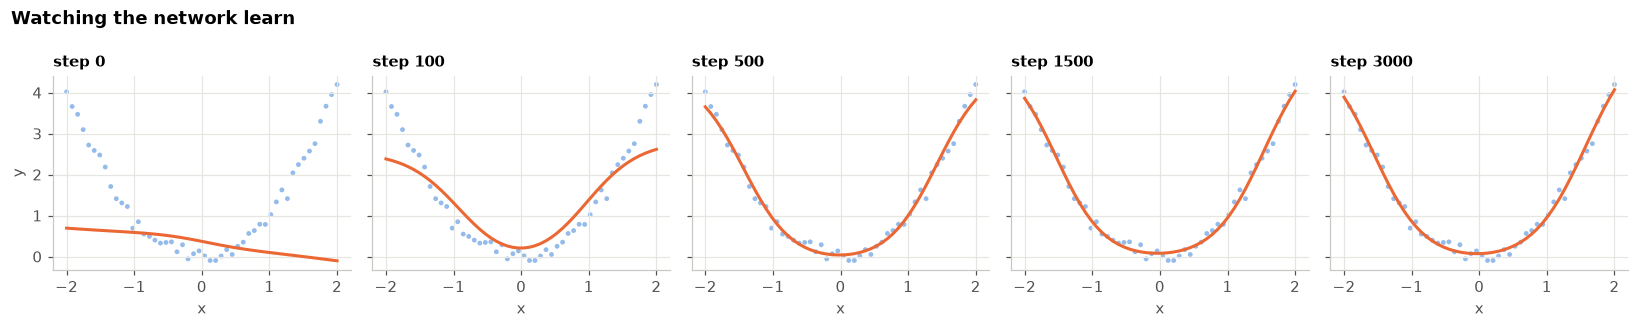

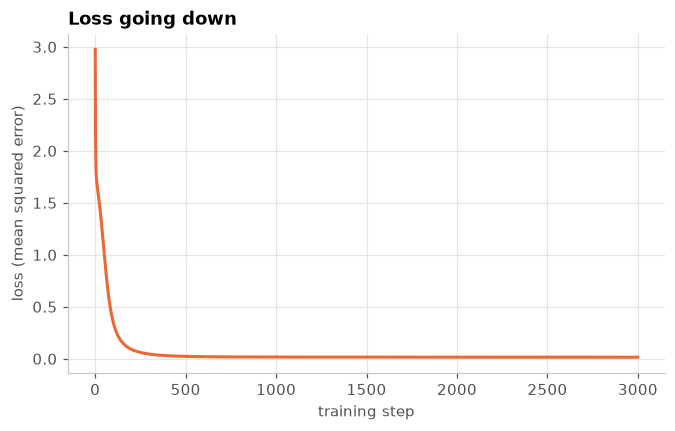

In [9]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(3 * len(snapshots), 3), sharey=True)
for ax, (step, pred) in zip(axes, sorted(snapshots.items())):
    ax.scatter(x, y, s=10, color=BLUE, alpha=0.5, edgecolor="none")
    ax.plot(x, pred, color=ORANGE, linewidth=2)
    ax.set_title(f"step {step}", fontsize=10)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.suptitle("Watching the network learn", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(losses, color=ORANGE, linewidth=2)
ax.set(xlabel="training step", ylabel="loss (mean squared error)", title="Loss going down")
plt.show()

## Step 7: Predict

The trained knobs *are* the model. To use it, run the forward pass on inputs it has never seen.

In [10]:
new_x = np.array([[-1.5], [0.0], [0.7], [1.9]])
prediction, _ = forward(new_x, W1, b1, W2, b2)

for xi, p in zip(new_x.ravel(), prediction.ravel()):
    print(f"x = {xi:5.2f}   network says {p:6.3f}   true x² = {xi**2:.3f}")

x = -1.50   network says  2.299   true x² = 2.250
x =  0.00   network says  0.070   true x² = 0.000
x =  0.70   network says  0.448   true x² = 0.490
x =  1.90   network says  3.785   true x² = 3.610


## Recap: the whole thing in 12 lines

```python
W1, b1, W2, b2 = init()                              # 1. initialise
for step in range(steps):
    h     = np.tanh(x @ W1 + b1)                     # 2. forward pass
    y_hat = h @ W2 + b2
    L     = np.mean((y_hat - y) ** 2)                # 3. loss
    d_y_hat = 2 * (y_hat - y) / n                    # 4. backward pass
    dW2, db2 = h.T @ d_y_hat, d_y_hat.sum(0)
    d_z1  = (d_y_hat @ W2.T) * (1 - h ** 2)
    dW1, db1 = x.T @ d_z1, d_z1.sum(0)
    W1 -= lr * dW1; b1 -= lr * db1                   # 5. update
    W2 -= lr * dW2; b2 -= lr * db2                   # 6. (the loop is the repeat)
y_new = np.tanh(x_new @ W1 + b1) @ W2 + b2           # 7. predict
```

| Step | What it is | Where it lives in the code |
|---|---|---|
| 0 Data | inputs and correct answers | `x`, `y` |
| 1 Initialise | random starting knobs | `W1, b1, W2, b2 = ...` |
| 2 Forward pass | inputs → prediction | `forward()` |
| 3 Loss | how wrong, as one number | `loss()` |
| 4 Backward pass | gradient of the loss for every knob | `backward()` |
| 5 Update | knob −= lr × gradient | the four `-=` lines |
| 6 Repeat | loop steps 2 to 5 | `for step in range(steps)` |
| 7 Predict | forward pass on new data | `forward(new_x, ...)` |

### Try it yourself
- Change `4` hidden neurons to `1` or `2` in Step 1 and retrain. Can it still make the U shape?
- Change `lr` to `0.5` or `0.001`. What happens to the loss curve?
- Change the data to `y = np.sin(2 * x)`. Does it still work? How many hidden neurons does it need?

### Sanity check (optional)
Backprop is easy to get subtly wrong. The classic test: nudge one weight by a tiny amount by hand, see how much the loss
actually changes, and compare with what `backward()` claimed. They should agree to many decimal places.

In [11]:
eps = 1e-6
y_hat, h = forward(x, W1, b1, W2, b2)
claimed = backward(x, y, y_hat, h, W2)[0][0, 0]        # backprop's gradient for W1[0, 0]

W1[0, 0] += eps;  loss_up   = loss(forward(x, W1, b1, W2, b2)[0], y)
W1[0, 0] -= 2*eps; loss_down = loss(forward(x, W1, b1, W2, b2)[0], y)
W1[0, 0] += eps                                          # put it back
measured = (loss_up - loss_down) / (2 * eps)

print(f"backprop says  {claimed:.8f}")
print(f"measured       {measured:.8f}")

backprop says  -0.00015288
measured       -0.00015288
